# Performing DEG Pathway analysis (limma, R) on Pseudobulking from atlas
* Ovarian cancer samples only
* dataframes made previously (2026-04-10_PseudobulkingSampleType_fromNRcode.jpynb), separate for each DC subset and each has seperate metadata file
* Using modified code from ChatGPT -18/6/26

* Use R_env

In [3]:
library(limma)
library(edgeR)
library(dplyr)
library(RColorBrewer)
library(Seurat)
library(ggplot2)
library(pheatmap)
library(ggrepel)

In [4]:
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code")

### Read in the Pseudobulk DEGs

In [5]:
#tt1 is primary vs metastatic
tt1_dc1 <- read.csv("Pseudobulk/OC_DC1/tt1_DC1.csv", row.names = 1)
tt1_dc2 <- read.csv("Pseudobulk/OC_DC2/tt1_DC2.csv", row.names = 1)
tt1_mregdc <- read.csv("Pseudobulk/OC_mregDC/tt1_mregDC.csv", row.names = 1)

In [6]:
#tt3 is primary vs ascites
tt3_dc1 <- read.csv("Pseudobulk/OC_DC1/tt3_DC1.csv", row.names = 1)
tt3_dc2 <- read.csv("Pseudobulk/OC_DC2/tt3_DC2.csv", row.names = 1)
tt3_mregdc <- read.csv("Pseudobulk/OC_mregDC/tt3_mregDC.csv", row.names = 1)

## Read in Pseudobulked data from 2026-04-24_OC_PseudobulkingSampleType_fromNRcode.ipynb

In [7]:
#Pseudobulking was performed with 
#read in csv files for pseudobulked data
pseudobulk_DC1 <- read.csv("Pseudobulk/oc_pseudobulk_DC1_data.csv")
pseudobulk_DC2 <- read.csv("Pseudobulk/oc_pseudobulk_DC2_data.csv")
pseudobulk_mregDC <- read.csv("Pseudobulk/oc_pseudobulk_mregDC_data.csv")

In [8]:
#read in csv files for metadata
metadata_DC1 <- read.csv("Pseudobulk/oc_pseudobulk_sampletype_metadata_DC1.csv")
metadata_DC2 <- read.csv("Pseudobulk/oc_pseudobulk_sampletype_metadata_DC2.csv")
metadata_mregDC <- read.csv("Pseudobulk/oc_pseudobulk_sampletype_metadata_mregDC.csv")

## Read in seurat file

In [9]:
#read in data
data_all = readRDS('/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

In [10]:
head(data_all)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15629172,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.18922702,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.13527090,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.36721915,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.32900991,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.14672113,0.08149318,0.174721746,-0.17654256
GSE215120_AM1_ACTGAGTCAGGCTGAA-1,7117,1505,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,3.259800,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15998438,-0.05433711,-0.048045593,0.74123969
GSE215120_AM1_ACTGTCCGTCTCTTAT-1,7875,1515,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.930159,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15336146,-0.02565772,0.004267385,0.53398699
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887,1846,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.05677931,0.42842232,0.365930736,-0.08318085


In [11]:
#isolate ovarian cancer data
data_oc <- subset(x = data_all, subset = cancer_with_H == "HGSOC")

In [12]:
head(data_oc)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
PRJCA005422_EOC2_FS_cell_GTCAAGTTCTTCCTTC,798,375,Ascites,HGSOC,HGSOC2,PRJCA005422_HGSOC2_AS,6.641604,ascites fluid,ascites,HGSOC,⋯,Unknown,mregDC,ascites,HGSOC,HGSOC,Treatment naive,0.11536326,-0.18915448,-0.07653757,0.065129255
PRJCA005422_EOC1_FS_cell_AAACCTGGTCGGCTCA,11773,2471,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.089527,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.61736327,-0.26521783,-0.15411653,-0.014471042
PRJCA005422_EOC1_FS_cell_AAACCTGTCATCATTC,15590,2937,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.411802,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.75713461,-0.23151705,-0.10016430,-0.001964239
PRJCA005422_EOC1_FS_cell_AAAGTAGCATCCGCGA,19965,3350,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,1.707989,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.58801287,-0.25292192,-0.14645768,-0.047835198
PRJCA005422_EOC1_FS_cell_AAAGTAGTCAAGGCTT,11139,2545,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.154592,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC2,ascites,HGSOC,HGSOC,Treatment naive,0.08503905,0.05893854,-0.05944513,0.176611718
PRJCA005422_EOC1_FS_cell_AAATGCCAGGCAGGTT,16197,2862,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.259678,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.62685018,-0.26230508,-0.09604047,-0.033273711
PRJCA005422_EOC1_FS_cell_AAATGCCCACGGCTAC,15939,3270,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,3.764352,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC2,ascites,HGSOC,HGSOC,Treatment naive,0.05386841,0.31015898,0.28903050,-0.162544229
PRJCA005422_EOC1_FS_cell_AACCATGCAATGGATA,18314,3479,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,4.515671,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.67620028,-0.27857529,-0.06023078,-0.123786350
PRJCA005422_EOC1_FS_cell_AACCGCGAGCCAACAG,14613,2930,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.573051,ascites fluid,ascites,HGSOC,⋯,Unknown,cDC2,ascites,HGSOC,HGSOC,Treatment naive,0.05230055,0.41376189,0.10977246,-0.108408496


Set DC subset dataframes

In [13]:
data_dc1 <- subset (data_oc, subset = NR_annotations_simple == "cDC1")
data_dc2 <- subset (data_oc, subset = NR_annotations_simple == "cDC2")
data_mregdc <- subset (data_oc, subset = NR_annotations_simple == "mregDC")

## Start by looking at Primary vs Metastatic first

In [14]:
head(tt1_dc1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOSB,FOSB,14192,-6.296804,7.277445,-10.322329,2.602494e-20,2.601713e-16,35.15871
COL1A2,COL1A2,5834,-5.243841,2.816614,-8.639858,1.760841e-15,8.801562e-12,24.31056
CXCR4,CXCR4,2150,-4.698578,7.427939,-7.388013,3.917982e-12,1.305602e-08,17.13263
NR4A1,NR4A1,9530,-4.245668,7.017105,-7.087584,2.267957e-11,4.699024e-08,15.45282
COL1A1,COL1A1,12509,-4.794828,2.971580,-7.081416,2.350217e-11,4.699024e-08,15.33050
RGS1,RGS1,1265,-4.721053,7.965060,-6.953391,4.903455e-11,8.169973e-08,14.72184


In [15]:
#choose top genes by adjusted p value
top100_dc1 <- rownames(
    tt1_dc1 %>%
        arrange(adj.P.Val) %>%
        head(100)
)


top100_dc2 <- rownames(
    tt1_dc2 %>%
        arrange(adj.P.Val) %>%
        head(100)
)


top100_mregdc <- rownames(
    tt1_mregdc %>%
        arrange(adj.P.Val) %>%
        head(100)
)

In [35]:
head(top100_dc1)

[1] "FOSB"   "COL1A2" "CXCR4"  "NR4A1"  "COL1A1" "RGS1"

## DC1

In [99]:
head(tt1_dc1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
FOSB,FOSB,14192,-6.296804,7.277445,-10.322329,2.602494e-20,2.601713e-16,35.15871,FOSB
COL1A2,COL1A2,5834,-5.243841,2.816614,-8.639858,1.760841e-15,8.801562e-12,24.31056,COL1A2
CXCR4,CXCR4,2150,-4.698578,7.427939,-7.388013,3.917982e-12,1.305602e-08,17.13263,CXCR4
NR4A1,NR4A1,9530,-4.245668,7.017105,-7.087584,2.267957e-11,4.699024e-08,15.45282,NR4A1
COL1A1,COL1A1,12509,-4.794828,2.971580,-7.081416,2.350217e-11,4.699024e-08,15.33050,COL1A1
RGS1,RGS1,1265,-4.721053,7.965060,-6.953391,4.903455e-11,8.169973e-08,14.72184,RGS1


In [19]:
options(repr.plot.width=12, repr.plot.height=12)

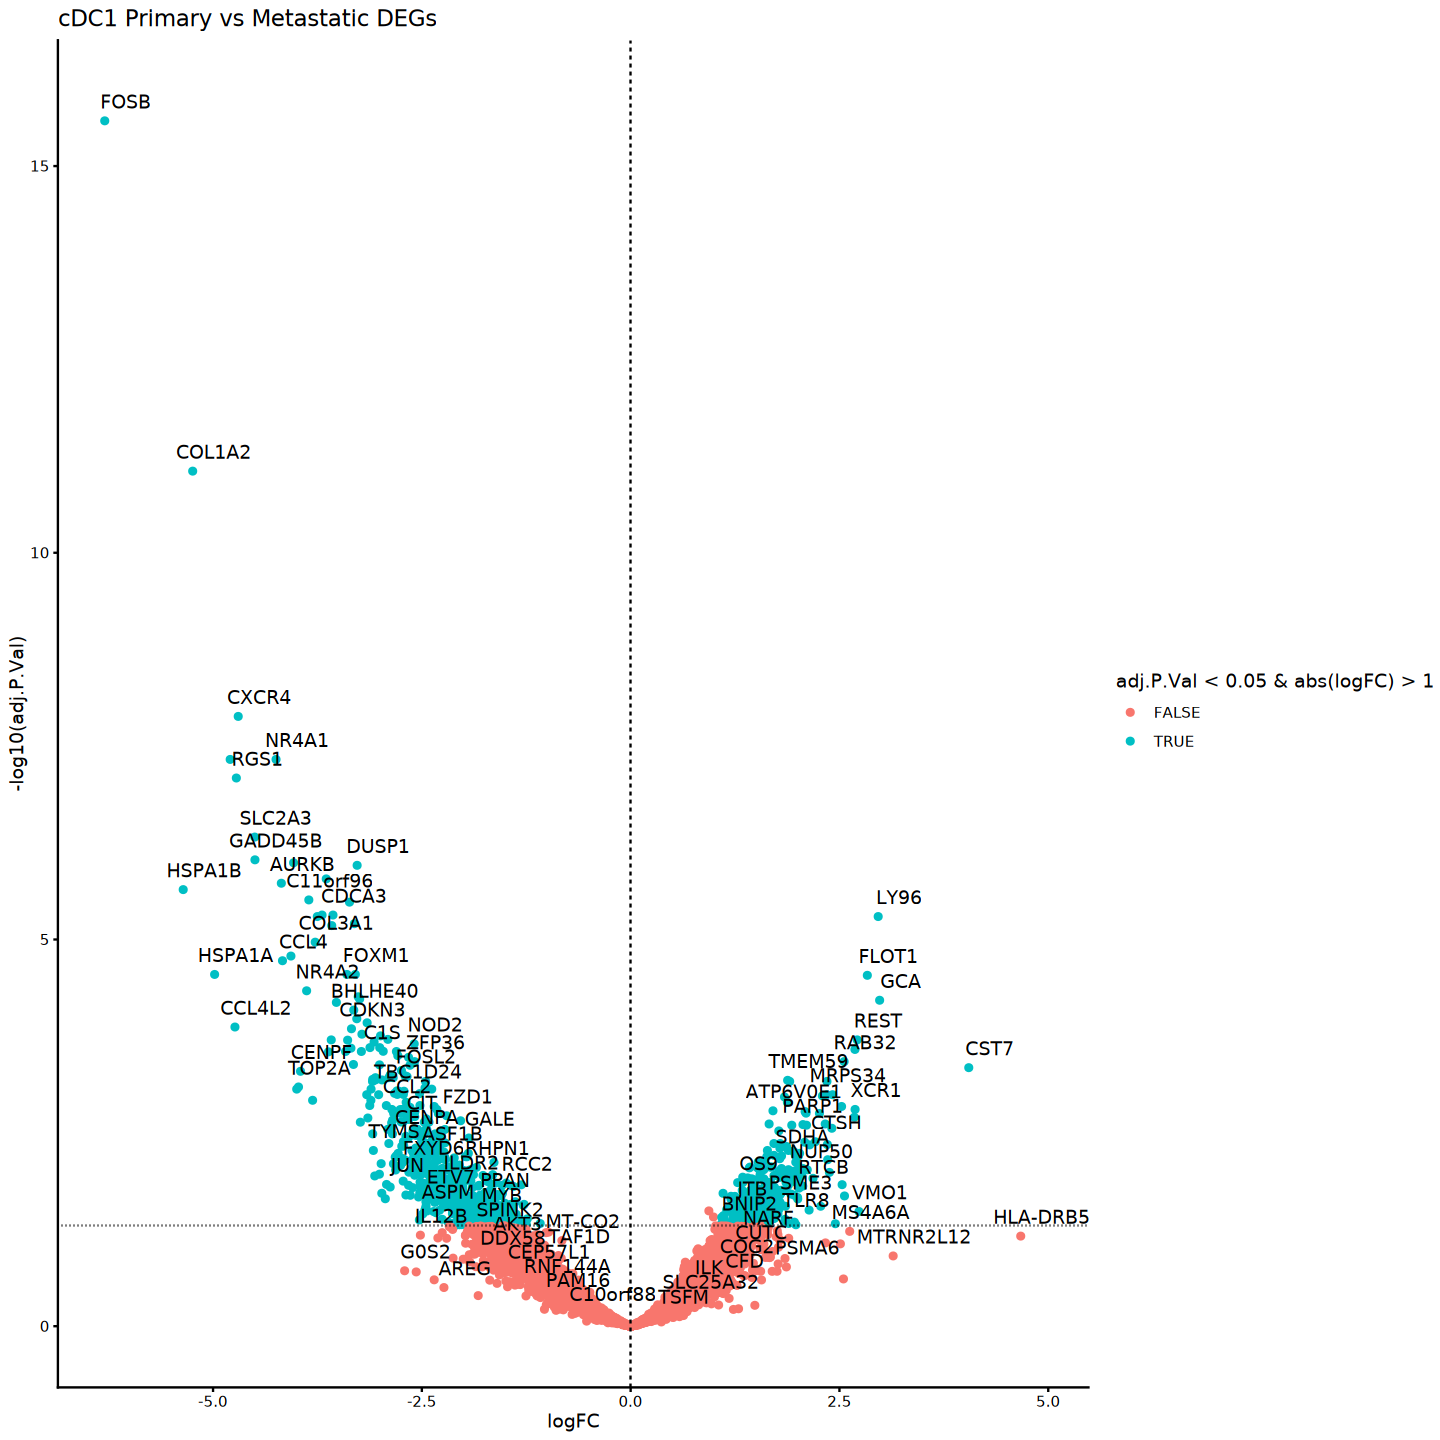

In [21]:
tt1_dc1$gene <- rownames(tt1_dc1)

ggplot(tt1_dc1,
       aes(logFC, -log10(adj.P.Val), label = gene)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(tt1_dc1$gene), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "cDC1 Primary vs Metastatic DEGs")

* negative logFC values here are higher in primary compared to metastatic
* positive logFC  values are higher in metastatic compared to primary
* the red log10 adj p values show that there is no significant difference between the two groups

In [102]:
head(top100_dc1)

[1] "FOSB"   "COL1A2" "CXCR4"  "NR4A1"  "COL1A1" "RGS1"

In [22]:
library(vioplot)

Loading required package: sm

Package 'sm', version 2.2-6.0: type help(sm) for summary information

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




In [23]:
#Filter data_dc1 to be only primary and metastatic
data_dc1 <- subset(data_dc1, sample_type_major2 %in% c("primary tumour", "metastatic tumour"))

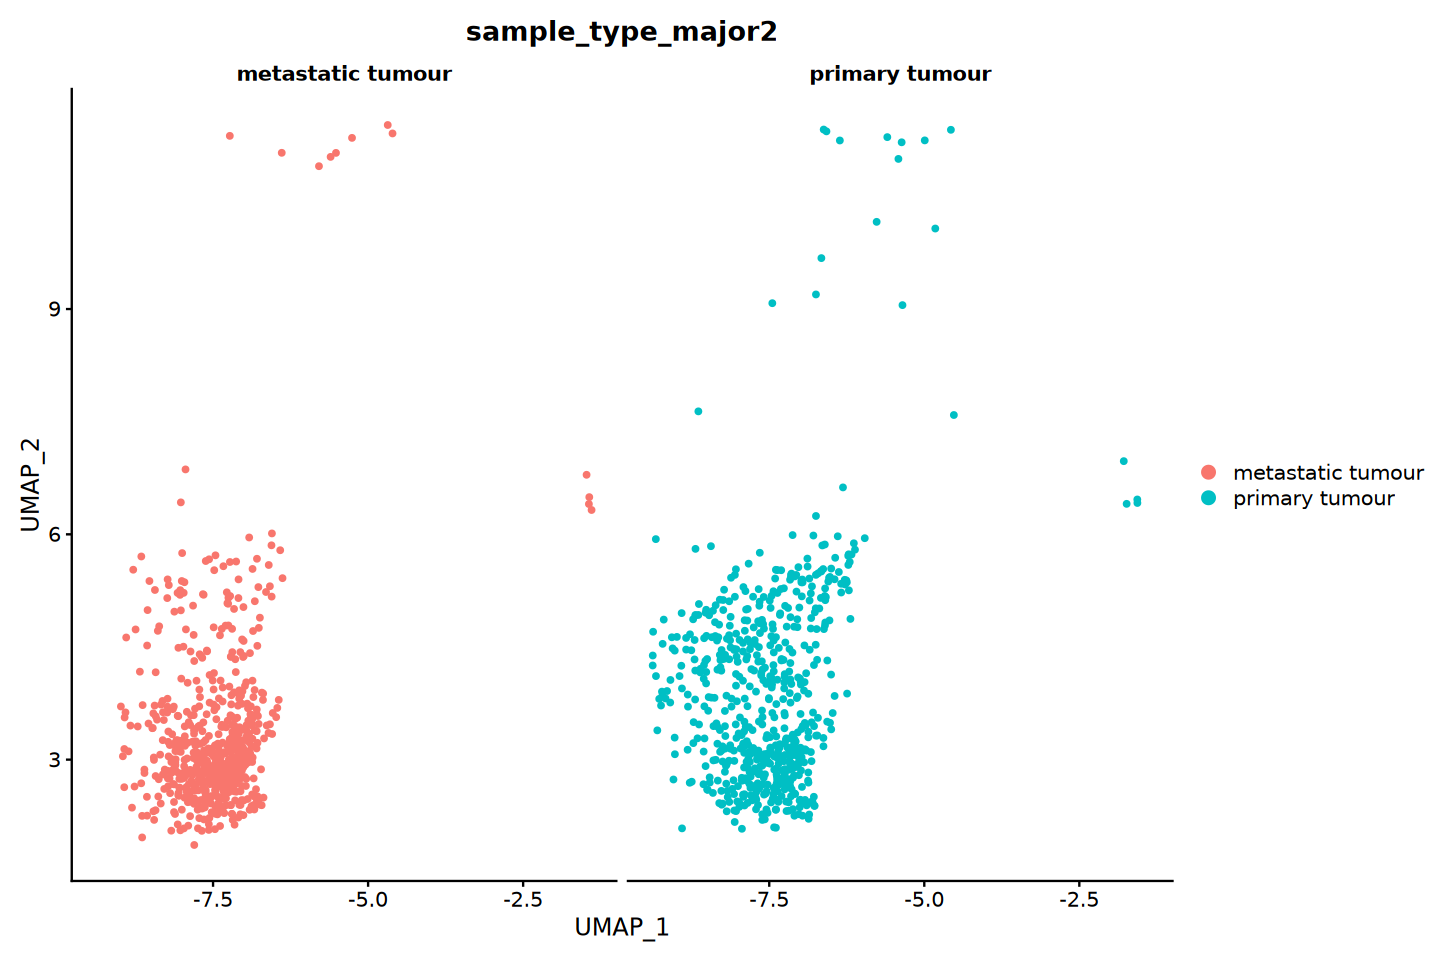

In [105]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_dc1, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

Warning message:
“The following requested variables were not found: NR4A1”


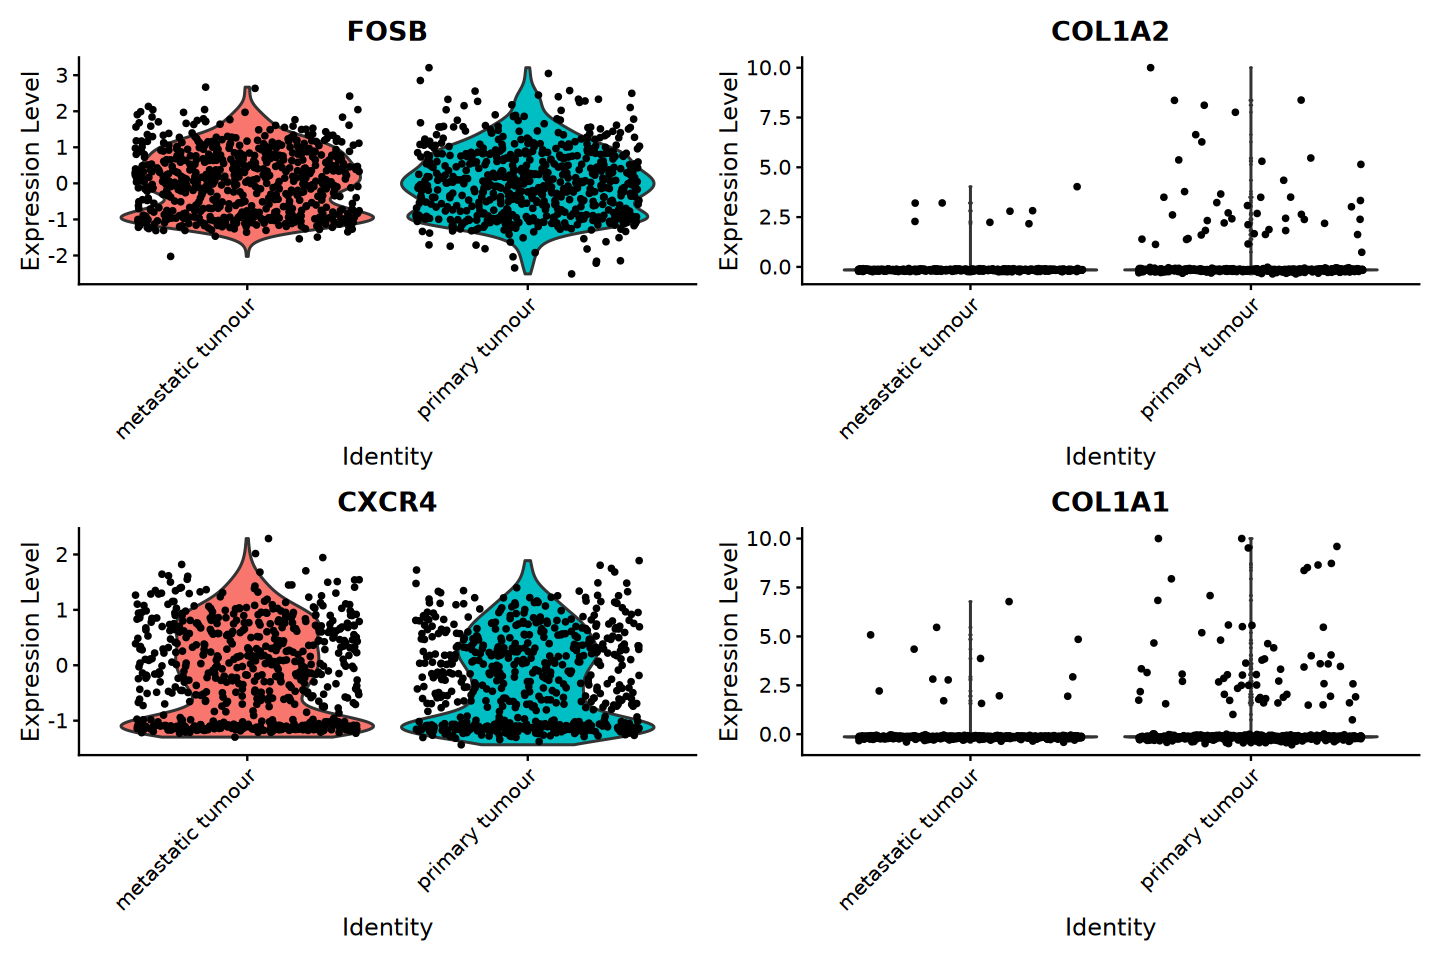

In [112]:
VlnPlot(data_dc1, features = top100_dc1[1:5], group.by = "sample_type_major2", ncol = 2)+
geom_boxplot(width = 0.1, color = "black", alpha = 0.5, outlier.shape = NA) + 
theme(legend.position = "none")

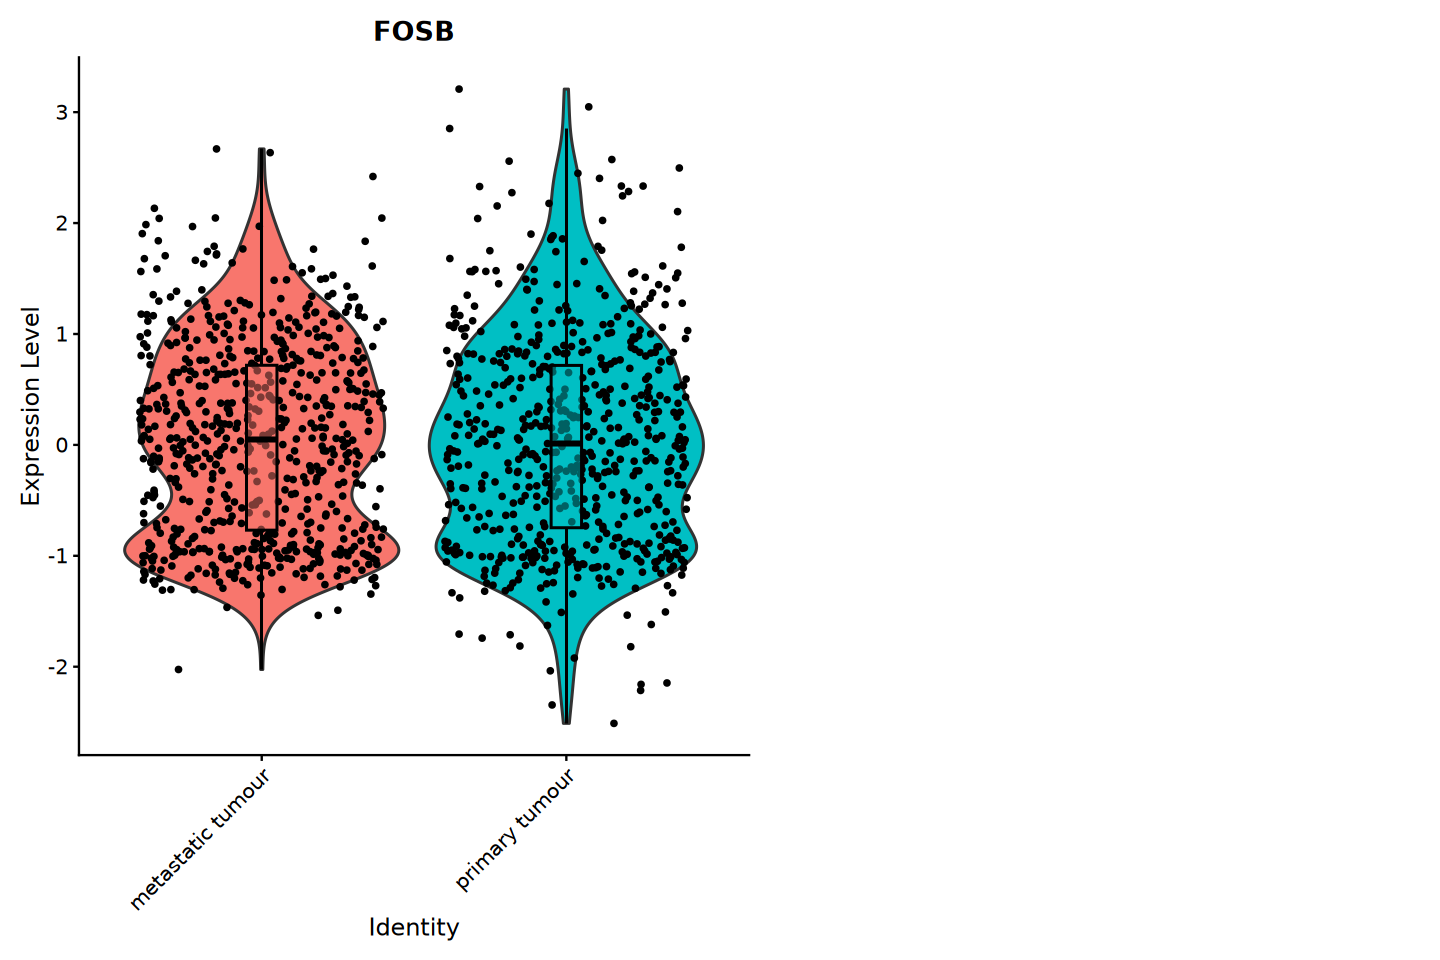

In [114]:
VlnPlot(data_dc1, features = "FOSB", group.by = "sample_type_major2", ncol = 2)+ 
  geom_boxplot(width = 0.1, color = "black", alpha = 0.5, outlier.shape = NA) + 
  theme(legend.position = "none")

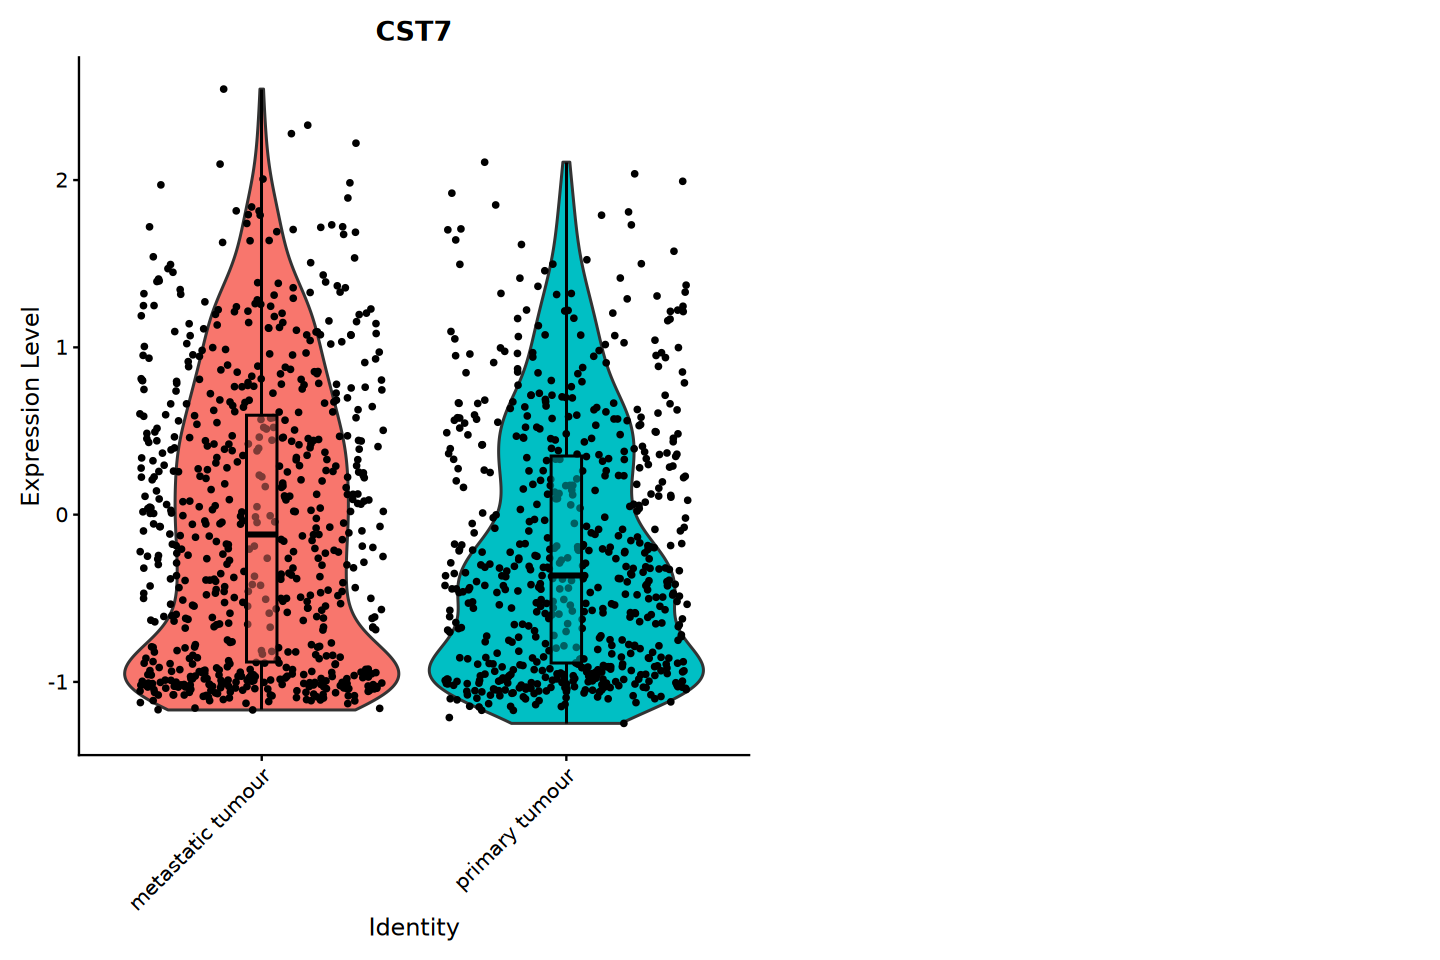

In [107]:
VlnPlot(data_dc1, features = "CST7", group.by = "sample_type_major2", ncol = 2)+ 
  geom_boxplot(width = 0.1, color = "black", alpha = 0.5, outlier.shape = NA) + 
  theme(legend.position = "none")

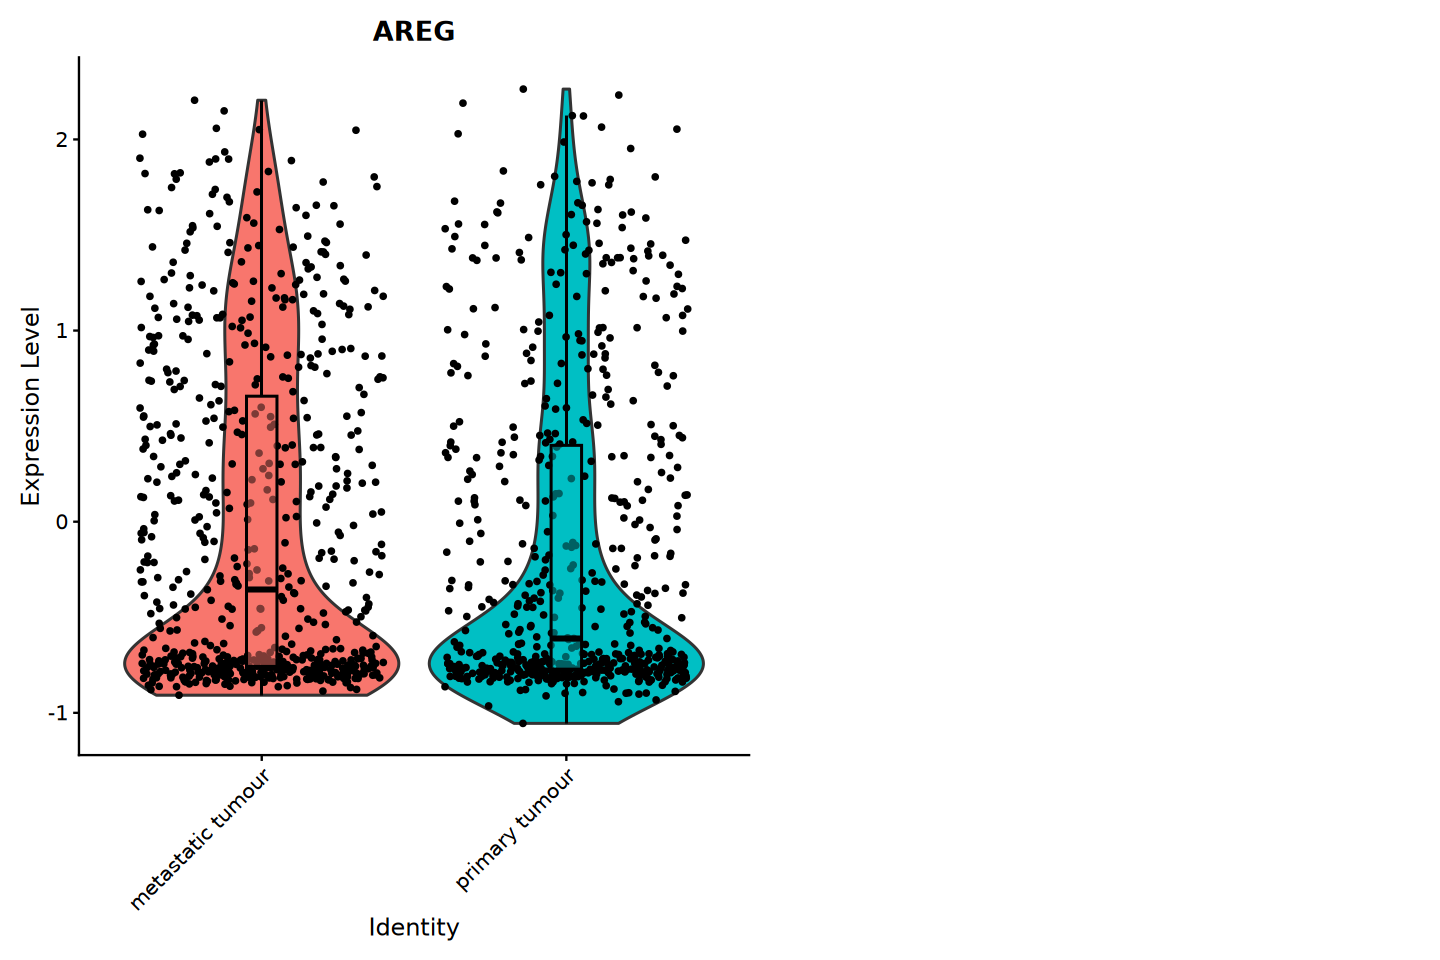

In [113]:
VlnPlot(data_dc1, features = "AREG", group.by = "sample_type_major2", ncol = 2)+ 
  geom_boxplot(width = 0.1, color = "black", alpha = 0.5, outlier.shape = NA) + 
  theme(legend.position = "none")

Warning message:
“The following requested variables were not found: NR4A1”


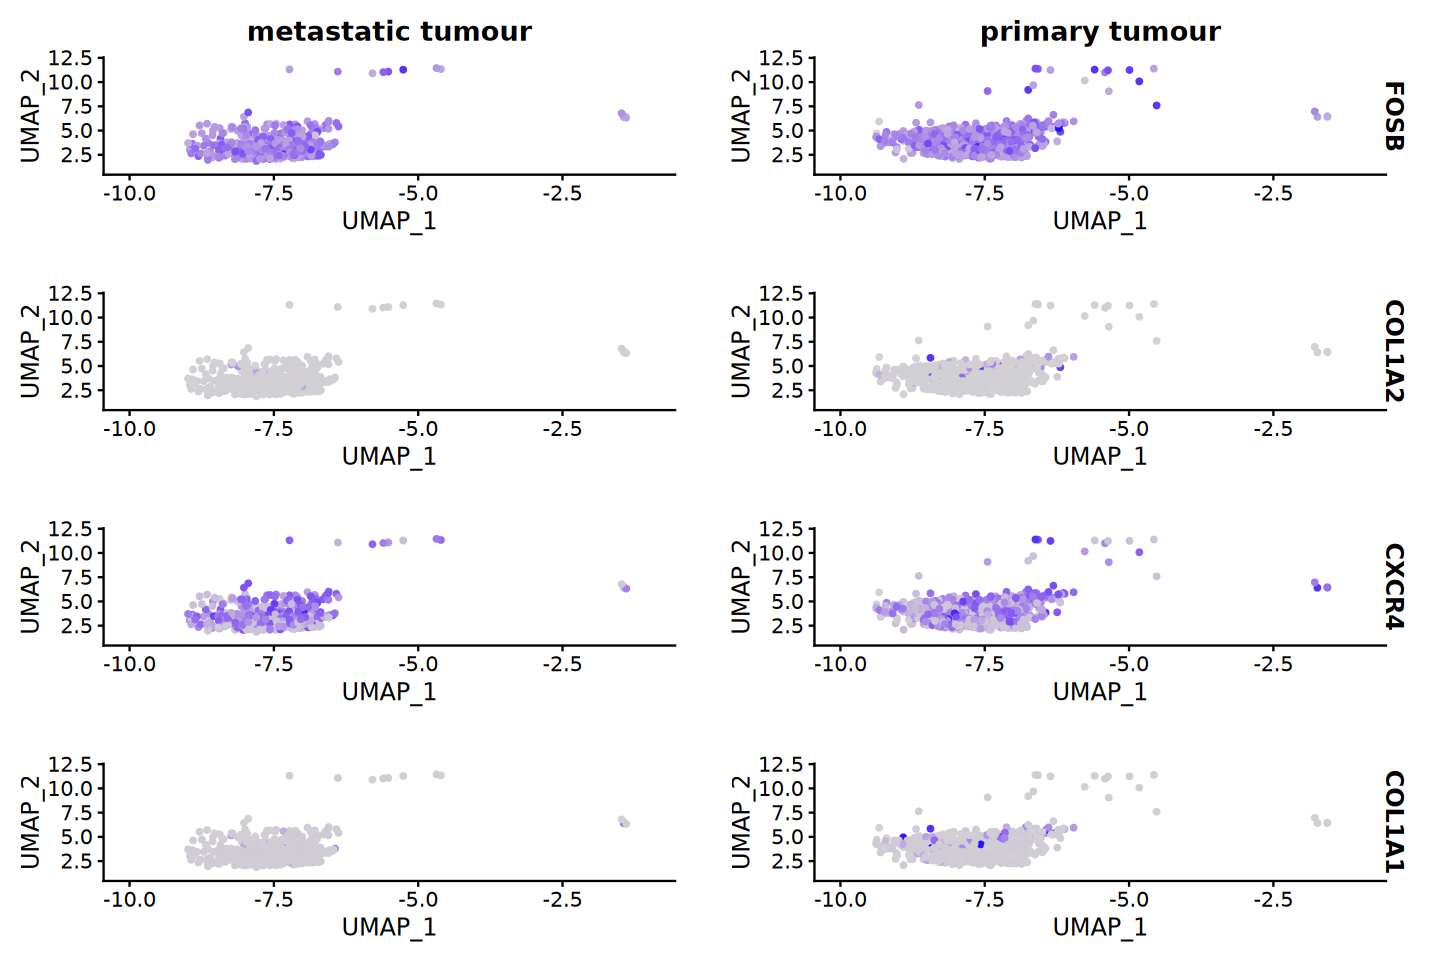

In [109]:
FeaturePlot(data_dc1, features = top100_dc1[1:5], split.by = "sample_type_major2")

In [110]:
#ggplot(deg1, aes(x = logFC, y = -log10(adj.P.Val), label = X)) +
 # geom_point(aes(color = adj.P.Val < 0.05 & abs(logFC) > 1)) +
  #scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  #labs(title = "cDC1 Volcano plot",
   # x = "logFC (Primary vs Metastatic)",
    #y = "-log10(adj. p-value)",
    #color = "Significant") +
  #geom_label( linewidth = NA)+
  #geom_text_repel(size = 3,  max.overlaps = 5, segment.colour = NA) +
  #geom_label(aes(label = X), position = position_dodge(0.9), max.overlaps = 5)+
  #geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  #geom_hline(yintercept = c(1), linetype = "dotted", color = "black") +
  #theme_minimal(base_size = 12)


In [111]:
 #(ggplot(deg1, aes(x = logFC, y = -log10(adj.P.Val), label = X)) +
  #geom_point(aes(color = adj.P.Val < 0.05 & abs(logFC) > 1), size = 3) +
  #geom_text(size = 3, nudge_y = 0.5) +
  #geom_text_repel(max.overlaps = 5)+
  #scale_colour_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00"))+
  #geom_vline(xintercept = c(0), linetype = "solid", color = "black") +
  #geom_hline(yintercept = c(0), linetype = "solid", color = "black") +
  #theme_minimal() +
  #labs(title = "cDC1 Volcano plot",
   # x = "logFC (Primary vs Metastatic)",
   # y = "-log10(adj. p-value)") +
  #theme(legend.position = "top")

## DC2

In [44]:
head(tt1_dc2)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
FOSB,FOSB,14192,-7.172775,8.061751,-16.44486,3.454625e-38,3.872290e-34,75.59583,FOSB
NR4A2,NR4A2,2181,-6.283017,8.034056,-14.33984,5.913278e-32,3.314096e-28,61.62468,NR4A2
NR4A1,NR4A1,9530,-5.817679,7.428508,-11.95837,7.459203e-25,2.787007e-21,45.67630,NR4A1
PTGS2,PTGS2,1262,-6.713193,5.891439,-11.64059,6.504013e-24,1.822587e-20,43.48866,PTGS2
ATF3,ATF3,1401,-5.565390,7.097458,-11.37864,3.851633e-23,8.634590e-20,41.82205,ATF3
GPR183,GPR183,10247,-4.562681,9.016367,-11.16021,1.688578e-22,3.154545e-19,40.46262,GPR183


In [ ]:
#Filter data_dc2 to be only primary and metastatic
data_dc2 <- subset(data_dc2, sample_type_major2 %in% c("primary tumour", "metastatic tumour"))

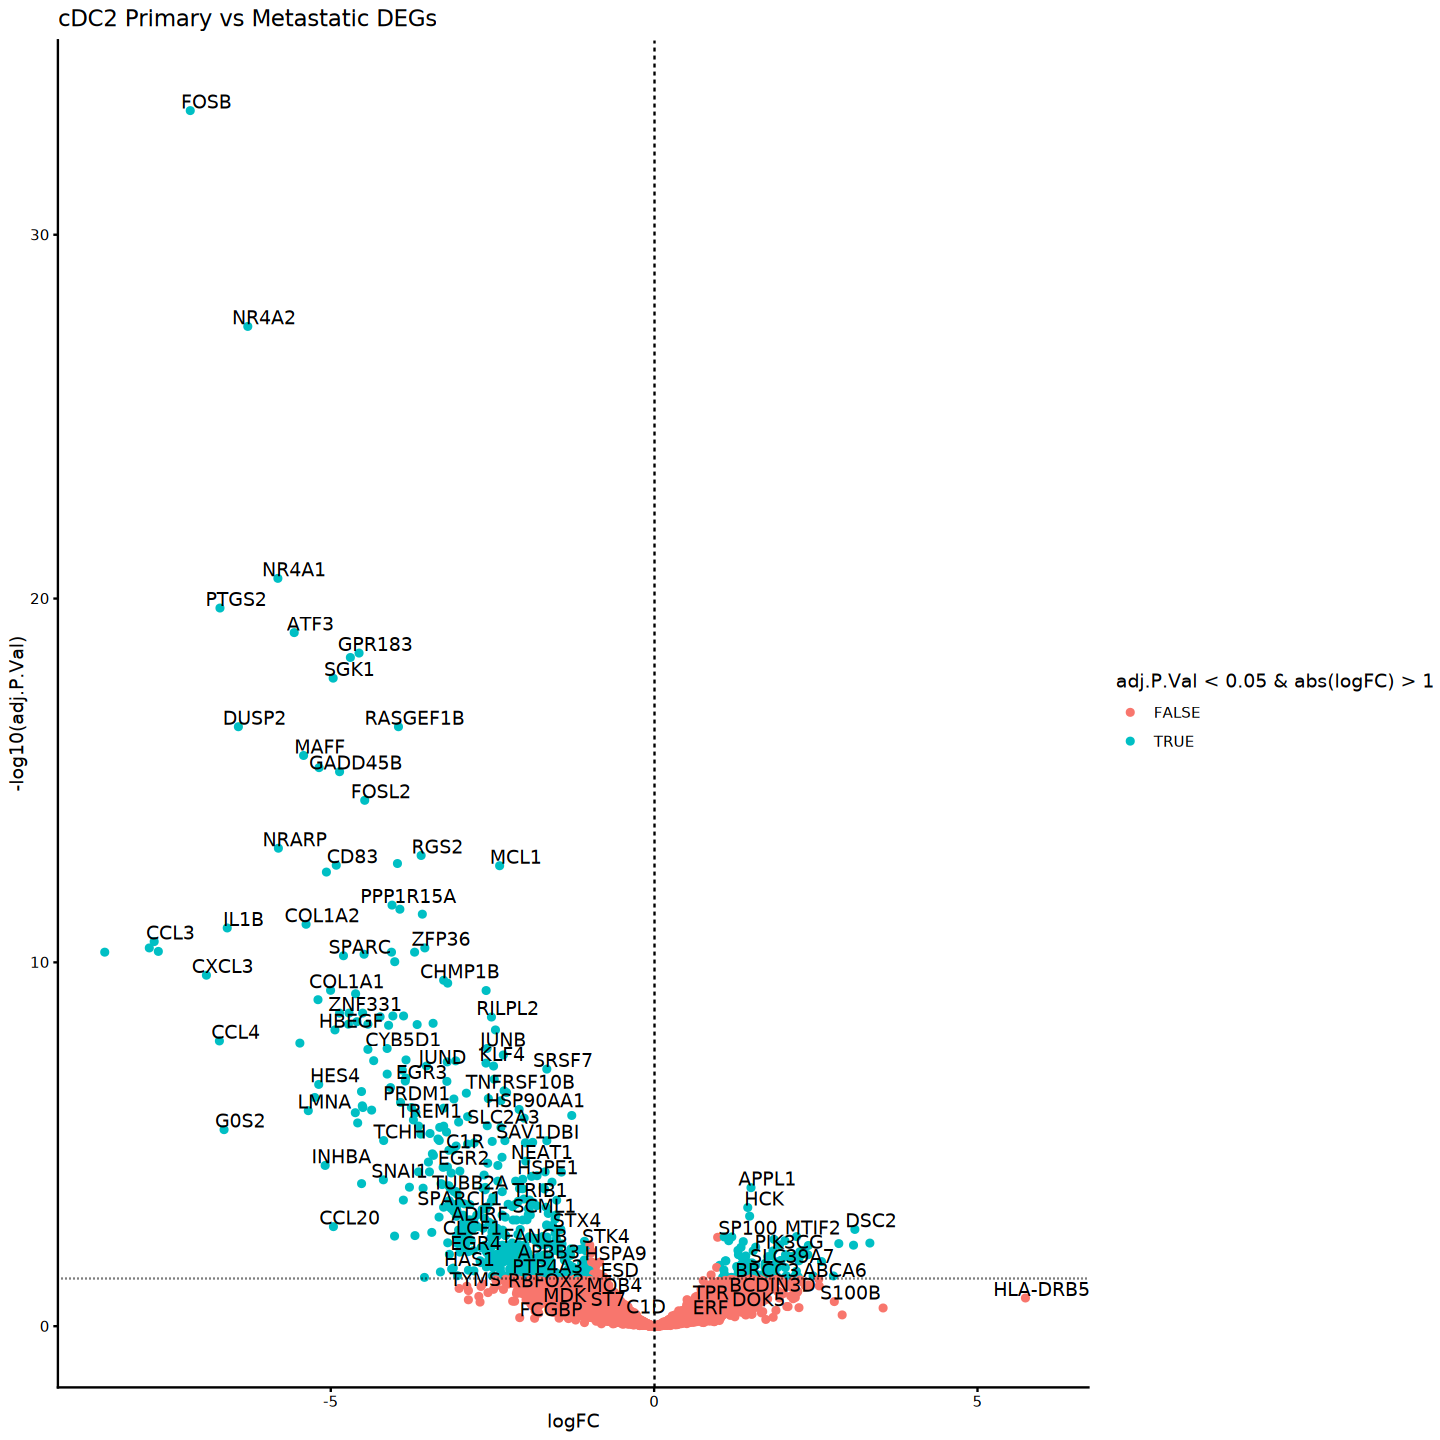

In [43]:
tt1_dc2$gene <- rownames(tt1_dc2)

ggplot(tt1_dc2,
       aes(logFC, -log10(adj.P.Val), label = gene)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(tt1_dc2$gene), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "cDC2 Primary vs Metastatic DEGs")

## mregDC

In [46]:
head(tt1_mregdc)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TYROBP,TYROBP,13983,5.569684,10.029229,4.889259,2.067751e-06,0.01768548,4.389553
RPS15A,RPS15A,11428,4.338221,10.945403,4.648081,6.057856e-06,0.02590642,3.476500
SLC25A6,SLC25A6,6190,4.443334,8.739950,4.419996,1.613761e-05,0.03369127,2.630757
RPS3A,RPS3A,3890,4.188353,11.250495,4.293620,2.733791e-05,0.03369127,2.201090
ZC3H12C,ZC3H12C,8499,-4.432971,3.956478,-4.274173,2.961797e-05,0.03369127,2.127371
RPS8,RPS8,477,3.588908,11.325386,4.221489,3.674576e-05,0.03369127,1.969344


In [26]:
#Filter data_mregdc to be only primary and metastatic
data_mregdc <- subset(data_mregdc, sample_type_major2 %in% c("primary tumour", "metastatic tumour"))

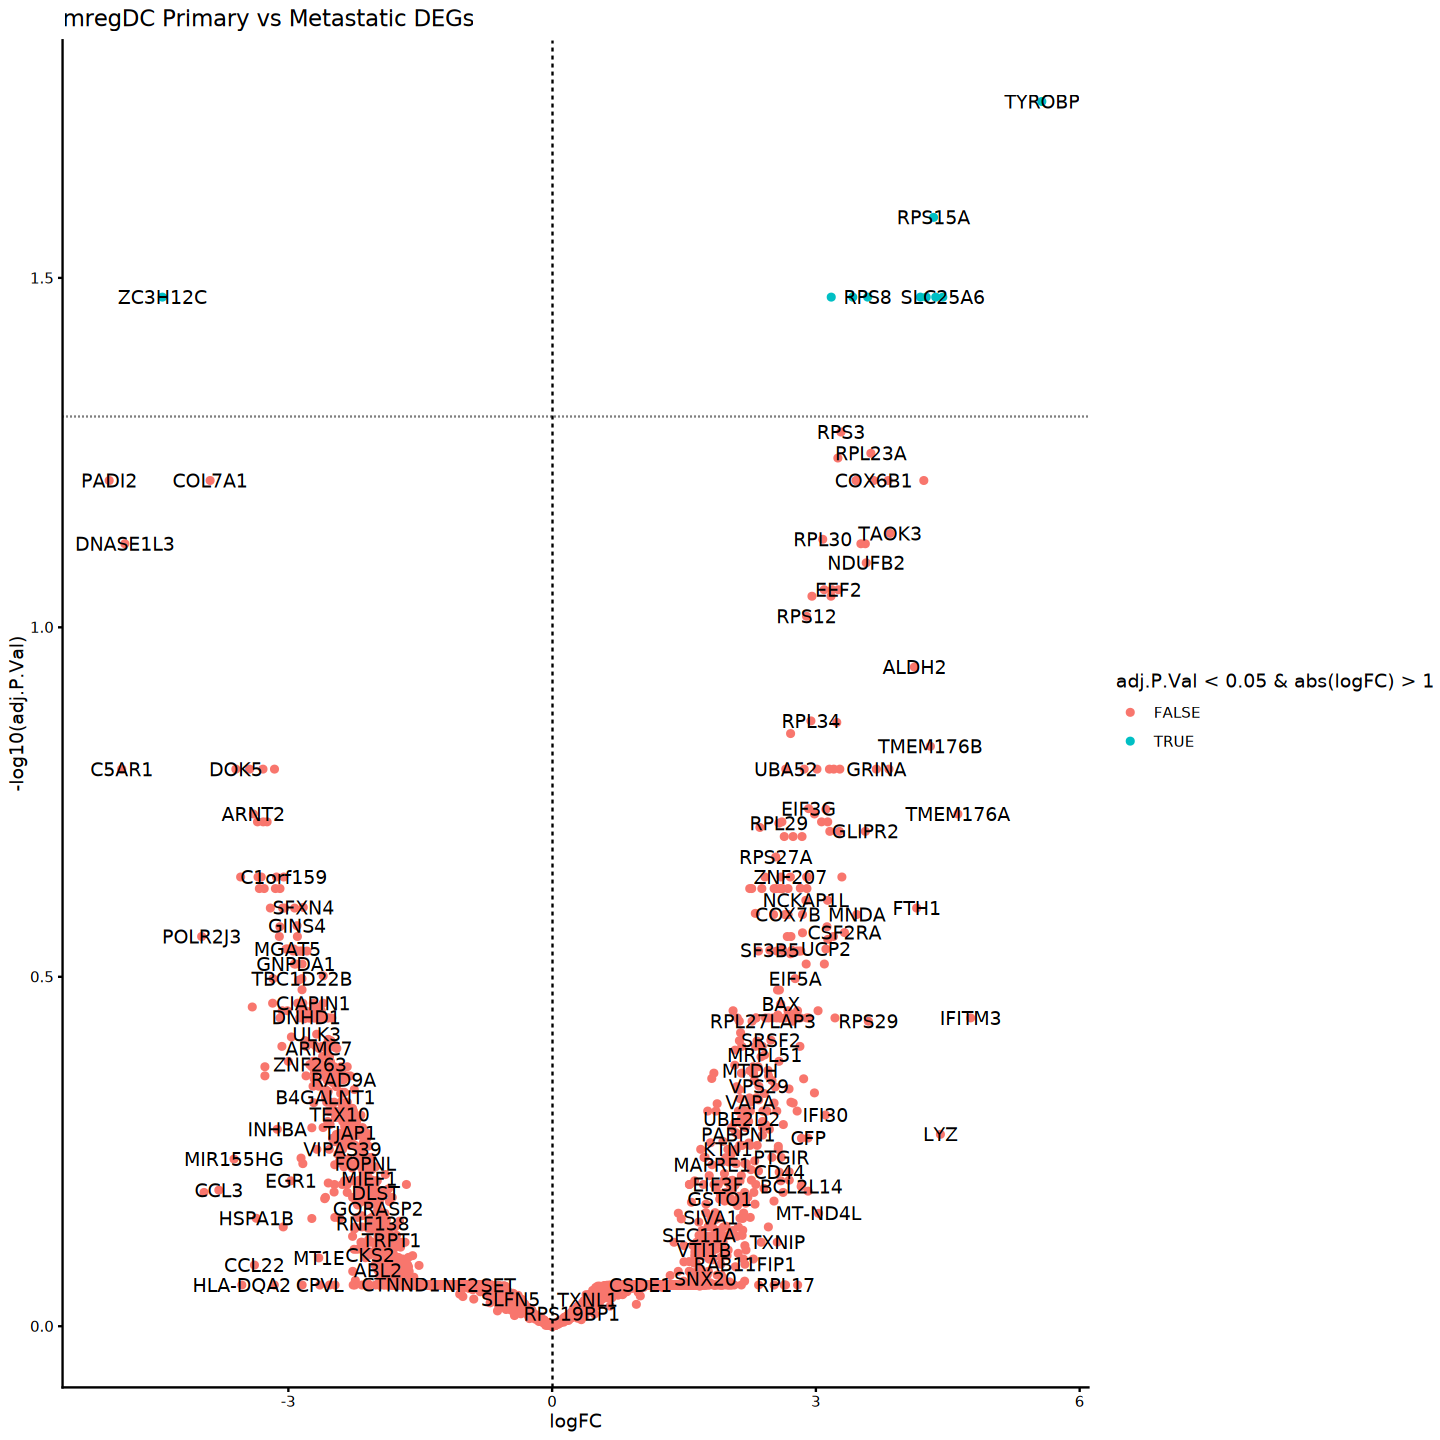

In [25]:
tt1_mregdc$gene <- rownames(tt1_mregdc)

ggplot(tt1_mregdc,
       aes(logFC, -log10(adj.P.Val), label = gene)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(tt1_mregdc$gene), 
    #nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "mregDC Primary vs Metastatic DEGs")

Warning message:
“The following requested variables were not found: TYROBP, RPS15A, SLC25A6, RPS3A”


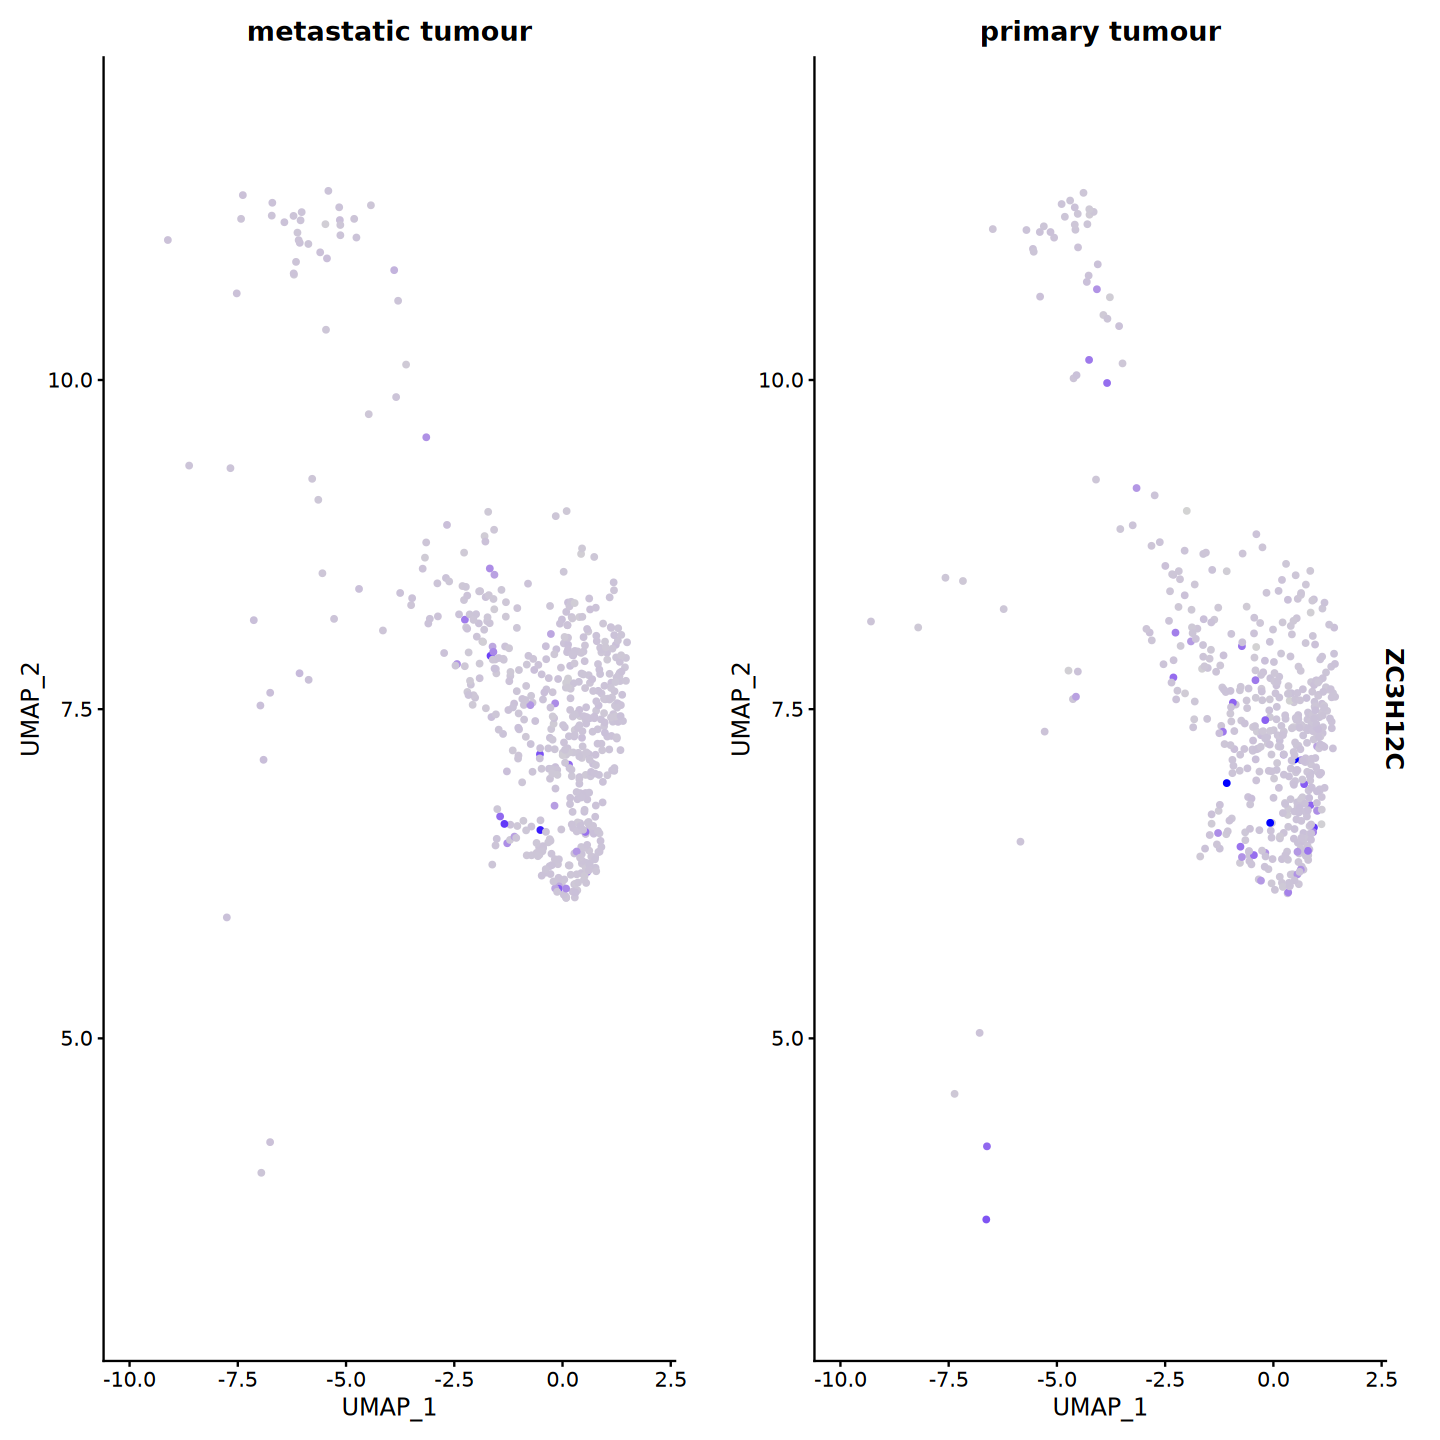

In [27]:
FeaturePlot(data_mregdc, features = top100_mregdc[1:5], split.by = "sample_type_major2")

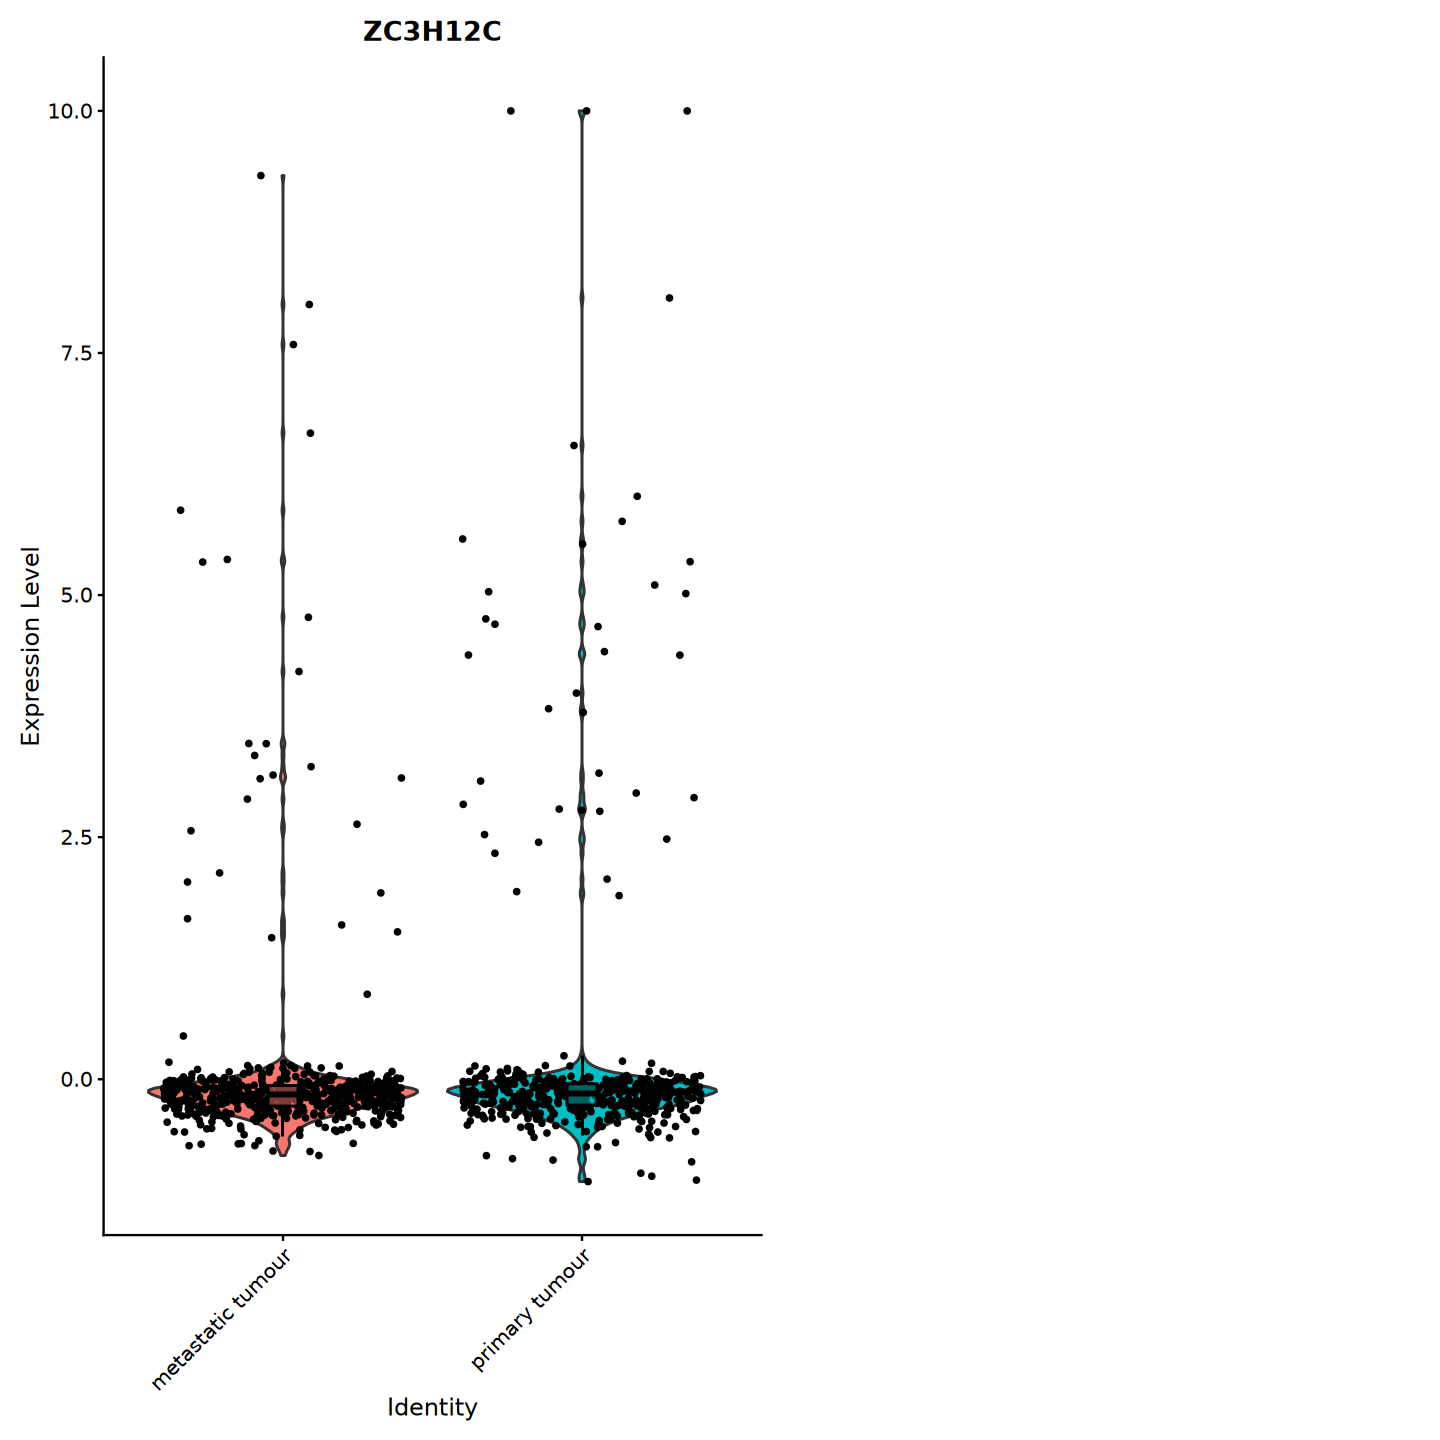

In [28]:
VlnPlot(data_mregdc, features = "ZC3H12C", group.by = "sample_type_major2", ncol = 2)+ 
  geom_boxplot(width = 0.1, color = "black", alpha = 0.5, outlier.shape = NA) + 
  theme(legend.position = "none")